# GLARE (receita fiel) aplicado ao Dataset3

Reimplementação do pipeline de treino/avaliação do GLARE (`glare/model.py`, `glare/data.py`, `glare/train.py`, config `..._rc_augment_best_hpo_final.yaml`) lendo **seu** formato: `Data/<Dataset>/Train/*.fa` e `Test/*.fa` (um FASTA por classe).

**Única mudança intencional:** `base_model` = `NTv3_8M_pre` (o GLARE usa `NTv3_650M_pre`) e o conjunto de classes = as do D3. Todo o resto segue o código do GLARE.

| Item | Seu notebook antigo | GLARE (esta versão) |
|---|---|---|
| Head | hidden encolhido p/ 256 (256→256→128) | sempre 512→256, dropout 0.2232 |
| Pooling | mean (ok) | mean mascarado (igual) |
| Avaliação | só os primeiros 4096 nt | janelas deslizantes (50% overlap), média dos logits por sequência |
| Seleção de checkpoint | menor val loss, patience 5 | maior F1 ponderado na validação, patience 8 |
| Loss | CE + LS 0.05 | CE ponderada `sqrt_inv` + LS 0.0465 |
| Otimizador | AdamW 5e-5 / 3e-4, wd 0.01, sem scheduler | AdamW 2.53e-5 / 2.89e-4, wd 0.0597, cosseno + 5% warmup |
| Batch | 8 | 8 × acumulação 4, `drop_last=True` |
| Precisão | fp16 sem GradScaler | bf16 autocast |
| Val split | 20%, seed 42 | 10% estratificado, seed 7 |
| Augment | RC antes do crop | crop aleatório e depois RC (p=0.5) |
| Tokenização | `add_special_tokens=False`, limpeza IUPAC→N | chamada idêntica à do GLARE; só `.upper()` |

In [1]:
!pip install -q scikit-learn matplotlib
# Se o carregamento do NTv3 falhar, o GLARE pina estas versões:
# !pip install -q "transformers>=4.40,<4.45" "tokenizers>=0.19,<0.20"

You should consider upgrading via the '/mnt/GIGANTE/doutorado-topicos-emergentes/.venv/bin/python -m pip install --upgrade pip' command.


In [2]:
import os, re, time, glob, math, random, inspect, importlib, sys
import numpy as np
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, AutoConfig, AutoModel, AutoModelForMaskedLM, get_cosine_schedule_with_warmup

os.environ["TOKENIZERS_PARALLELISM"] = "false"

# ------------------------- DADOS (único bloco "seu") -------------------------
DATASET   = "Dataset3"
DATA_ROOT = "./Data"
TRAIN_DIR = os.path.join(DATA_ROOT, DATASET, "Train")
TEST_DIR  = os.path.join(DATA_ROOT, DATASET, "Test")
EXTS = (".fa", ".fasta", ".fna")

# --------------- CONFIG = espelho do YAML best_hpo_final do GLARE ---------------
CFG = dict(
    base_model="InstaDeepAI/NTv3_8M_pre",   # GLARE: InstaDeepAI/NTv3_650M_pre
    max_length=4096,
    hidden_dim=512,
    head_dropout=0.22320323256729352,
    batch_size=8,
    max_epochs=10,
    patience=8,
    lambda_sf=1.0,
    backbone_lr=2.53032090218936e-05,
    head_lr=0.00028944361832243895,
    weight_decay=0.059703505248527425,
    warmup_fraction=0.05,
    val_fraction=0.1,
    seed=7,
    label_smoothing=0.04654581174590394,
    class_weight_scheme="sqrt_inv",
    grad_accum=4,            # YAML=4. O paper rodou em 4 GPUs (batch efetivo 128); em 1 GPU use 16 p/ igualar.
    rc_augment=True,
    overlap=0.5,
)
CKPT_PATH = "glare_d3_best.pt"

random.seed(CFG["seed"]); np.random.seed(CFG["seed"]); torch.manual_seed(CFG["seed"])
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_BF16 = device.type == "cuda" and torch.cuda.is_bf16_supported()
print("device:", device, "| bf16 autocast:", USE_BF16)
if device.type == "cuda" and not USE_BF16:
    print("AVISO: GPU sem bf16 (ex.: T4). Rodando em fp32 — único desvio imposto pelo hardware.")

/mnt/GIGANTE/doutorado-topicos-emergentes/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


device: cuda | bf16 autocast: True


In [3]:
# ============================ LEITURA DOS FASTA ============================
def ler_fasta(path):
    ids, seqs, cur_id, cur = [], [], None, []
    with open(path, errors="replace") as fh:
        for line in fh:
            line = line.strip()
            if not line: continue
            if line.startswith(">"):
                if cur_id is not None: ids.append(cur_id); seqs.append("".join(cur))
                cur_id, cur = line[1:], []
            else:
                cur.append(line)
    if cur_id is not None: ids.append(cur_id); seqs.append("".join(cur))
    return ids, seqs

def carregar_split(pasta, classes=None):
    arquivos = sorted(f for f in os.listdir(pasta) if f.lower().endswith(EXTS))
    nomes = [os.path.splitext(f)[0] for f in arquivos]
    if classes is None: classes = nomes
    recs = []
    for f, nome in zip(arquivos, nomes):
        _, seqs = ler_fasta(os.path.join(pasta, f))
        for s in seqs:   # GLARE: apenas .upper() (parse_panteon_fasta)
            recs.append({"sequence": s.upper(), "label": classes.index(nome)})
    return recs, classes

all_train, classes = carregar_split(TRAIN_DIR)
test_recs, _ = carregar_split(TEST_DIR, classes)
NUM_CLASSES = len(classes)

y_all = [r["label"] for r in all_train]
train_recs, val_recs = train_test_split(all_train, test_size=CFG["val_fraction"],
                                        random_state=CFG["seed"], stratify=y_all)
L = CFG["max_length"]
print(f"classes ({NUM_CLASSES}): {classes}")
print(f"train={len(train_recs)} val={len(val_recs)} test={len(test_recs)}")
print(f"seqs > {L} nt: train {np.mean([len(r['sequence'])>L for r in train_recs]):.1%} | "
      f"test {np.mean([len(r['sequence'])>L for r in test_recs]):.1%}  (nessas, a janela deslizante faz diferença)")

classes (12): ['Bel-Pao', 'CACTA', 'Copia', 'ERV', 'Gypsy', 'L1', 'Mariner', 'Mutator', 'PIF', 'Random', 'SINE', 'hAT']
train=47023 val=5225 test=6540
seqs > 4096 nt: train 19.7% | test 23.6%  (nessas, a janela deslizante faz diferença)


In [4]:
# ============================ TOKENIZER + DATASETS ============================
tokenizer = AutoTokenizer.from_pretrained(CFG["base_model"], trust_remote_code=True)
PAD_ID = tokenizer.pad_token_id if tokenizer.pad_token_id is not None else 0
RC_MAP = str.maketrans("ACGTacgt", "TGCAtgca")   # igual ao glare/data.py

def encode(seq):
    # chamada idêntica à de TEDataset/SlidingWindowDataset do GLARE
    enc = tokenizer(seq, return_tensors="pt", padding="max_length", truncation=True,
                    max_length=L, pad_to_multiple_of=128)
    ids = enc["input_ids"].squeeze(0)
    mask = enc["attention_mask"].squeeze(0) if "attention_mask" in enc else (ids != PAD_ID).long()
    return ids, mask

class TEDataset(Dataset):                      # treino (glare.data.TEDataset, augment=True)
    def __init__(self, recs, rc_augment): self.recs, self.rc = recs, rc_augment
    def __len__(self): return len(self.recs)
    def __getitem__(self, i):
        r = self.recs[i]; s = r["sequence"]
        if len(s) > L:                                   # 1) crop aleatório
            st = random.randint(0, len(s) - L); s = s[st:st+L]
        if self.rc and random.random() < 0.5:            # 2) reverse-complement
            s = s.translate(RC_MAP)[::-1]
        ids, mask = encode(s)
        return {"input_ids": ids, "attention_mask": mask,
                "label": torch.tensor(r["label"], dtype=torch.long)}

def sequence_windows(seq, max_length, overlap=0.5):   # cópia de glare.data.sequence_windows
    if len(seq) <= max_length: return [seq]
    stride = max(1, int(max_length * (1.0 - overlap)))
    out, start = [], 0
    while start < len(seq):
        end = min(start + max_length, len(seq)); out.append(seq[start:end])
        if end == len(seq): break
        start += stride
    return out

class SlidingWindowDataset(Dataset):           # val/teste (glare.data.SlidingWindowDataset)
    def __init__(self, recs, overlap):
        self.w = [(i, win, r["label"]) for i, r in enumerate(recs)
                  for win in sequence_windows(r["sequence"], L, overlap)]
        self.n_sequences = len(recs)
    def __len__(self): return len(self.w)
    def __getitem__(self, k):
        i, win, y = self.w[k]; ids, mask = encode(win)
        return {"input_ids": ids, "attention_mask": mask,
                "label": torch.tensor(y), "seq_idx": torch.tensor(i)}

NW = min(4, os.cpu_count() or 4)
def mk(ds, shuffle=False, drop_last=False):
    return DataLoader(ds, batch_size=CFG["batch_size"], shuffle=shuffle, drop_last=drop_last,
                      num_workers=NW, pin_memory=True, persistent_workers=NW > 0,
                      prefetch_factor=2 if NW > 0 else None)

train_loader = mk(TEDataset(train_recs, CFG["rc_augment"]), shuffle=True, drop_last=True)
val_ds  = SlidingWindowDataset(val_recs,  CFG["overlap"]); val_loader  = mk(val_ds)
test_ds = SlidingWindowDataset(test_recs, CFG["overlap"]); test_loader = mk(test_ds)
print(f"janelas: val={len(val_ds)} test={len(test_ds)}")

janelas: val=7468 test=10451


In [5]:
# ============================ MODELO (glare/model.py) ============================
class GLAREHead(nn.Module):
    # order_head omitido: no config final lambda_order=0 (sem efeito no treino/predição) e o D3 não tem 'order'.
    def __init__(self, input_dim, hidden_dim, num_classes, dropout):
        super().__init__()
        self.trunk = nn.Sequential(
            nn.Linear(input_dim, hidden_dim), nn.LayerNorm(hidden_dim), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(hidden_dim, hidden_dim // 2), nn.LayerNorm(hidden_dim // 2), nn.GELU(), nn.Dropout(dropout))
        self.superfamily_head = nn.Linear(hidden_dim // 2, num_classes)
    def forward(self, x): return self.superfamily_head(self.trunk(x))

def load_backbone(name):
    config = AutoConfig.from_pretrained(name, trust_remote_code=True)
    if device.type == "cuda" and not USE_BF16:        # só em GPU sem bf16
        for k in ("stem_compute_dtype", "down_convolution_compute_dtype",
                  "up_convolution_compute_dtype", "core_compute_dtype"):
            setattr(config, k, "float32")
    try:                                              # 1) AutoModel (backbone sem cabeça de MLM)
        return AutoModel.from_pretrained(name, config=config, trust_remote_code=True)
    except Exception as e1:
        print("AutoModel falhou:", repr(e1)[:200])
    try:                                              # 2) caminho do GLARE: NTv3PreTrained via módulo em cache
        hits = glob.glob(os.path.expanduser("~/.cache/huggingface/modules/transformers_modules/**/modeling_ntv3_pretrained.py"),
                         recursive=True)
        sys.path.insert(0, os.path.dirname(hits[0]))
        mod = importlib.import_module("modeling_ntv3_pretrained")
        return mod.NTv3PreTrained.from_pretrained(name, config=config, trust_remote_code=True)
    except Exception as e2:
        print("NTv3PreTrained falhou:", repr(e2)[:200])
    print("AVISO: usando AutoModelForMaskedLM (como no seu notebook antigo); confira o hidden size abaixo.")
    return AutoModelForMaskedLM.from_pretrained(name, config=config, trust_remote_code=True)

class GLAREModel(nn.Module):
    def __init__(self, name, num_classes):
        super().__init__()
        self.backbone = load_backbone(name)
        for p in self.backbone.parameters(): p.requires_grad = True       # full fine-tuning (use_lora=False)
        cfg = self.backbone.config
        hs = getattr(cfg, "hidden_size", None) or getattr(cfg, "d_model", None)
        if hs is None: hs = self._probe_hidden()
        self.hidden_size = int(hs)
        self.head = GLAREHead(self.hidden_size, CFG["hidden_dim"], num_classes, CFG["head_dropout"])
        sig = inspect.signature(self.backbone.forward).parameters
        self._kw = {k for k in ("input_ids", "attention_mask", "output_hidden_states") if k in sig}

    @torch.no_grad()
    def _probe_hidden(self):
        ids = torch.full((1, 128), PAD_ID if PAD_ID else 1, dtype=torch.long)
        return self._last_hidden(self.backbone(input_ids=ids, output_hidden_states=True)).shape[-1]

    @staticmethod
    def _last_hidden(o):                      # mesma ordem de preferência do GLARE
        if getattr(o, "hidden_states", None) is not None: return o.hidden_states[-1]
        if getattr(o, "last_hidden_state", None) is not None: return o.last_hidden_state
        return o[0]

    def forward(self, input_ids, attention_mask):
        kw = dict(input_ids=input_ids, attention_mask=attention_mask, output_hidden_states=True)
        h = self._last_hidden(self.backbone(**{k: v for k, v in kw.items() if k in self._kw}))
        m = attention_mask.unsqueeze(-1).float()                           # mean pool mascarado
        pooled = (h * m).sum(1) / m.sum(1).clamp(min=1)
        return self.head(pooled)

model = GLAREModel(CFG["base_model"], NUM_CLASSES).to(device)
n_tr = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"hidden_size do backbone = {model.hidden_size} | parâmetros treináveis = {n_tr/1e6:.1f}M")

AutoModel falhou: ValueError("Unrecognized configuration class <class 'transformers_modules.InstaDeepAI.ntv3_base_model.27682ed2f537a4c4fcc356b6b8201e7dfceca602.configuration_ntv3_pretrained.Ntv3PreTrainedConfig'> for 


Loading weights: 100%|██████████| 147/147 [00:00<00:00, 1408.78it/s]
[transformers] `use_return_dict` is deprecated! Use `return_dict` instead!


hidden_size do backbone = 256 | parâmetros treináveis = 8.0M


In [6]:
# ============================ LOSS, OTIMIZADOR, SCHEDULER ============================
def compute_class_weights(labels, num_classes, scheme="sqrt_inv"):   # cópia de glare.train
    counts = np.bincount(labels, minlength=num_classes).astype(float)
    present = counts > 0; w = np.zeros(num_classes)
    if scheme == "none": w[present] = 1.0
    elif scheme == "inv": w[present] = 1.0 / counts[present]; w[present] /= w[present].mean()
    else: w[present] = 1.0 / np.sqrt(counts[present]); w[present] /= w[present].mean()
    return torch.tensor(w, dtype=torch.float32)

cw = compute_class_weights([r["label"] for r in train_recs], NUM_CLASSES, CFG["class_weight_scheme"]).to(device)
criterion = nn.CrossEntropyLoss(weight=cw, label_smoothing=CFG["label_smoothing"])

optimizer = torch.optim.AdamW(
    [{"params": [p for p in model.backbone.parameters() if p.requires_grad], "lr": CFG["backbone_lr"]},
     {"params": list(model.head.parameters()), "lr": CFG["head_lr"]}],
    weight_decay=CFG["weight_decay"])

total_steps  = (len(train_loader) // CFG["grad_accum"]) * CFG["max_epochs"]
warmup_steps = int(total_steps * CFG["warmup_fraction"])
scheduler = get_cosine_schedule_with_warmup(optimizer, warmup_steps, total_steps)
print(f"optimizer steps totais={total_steps} warmup={warmup_steps}")

optimizer steps totais=14690 warmup=734


In [7]:
# ============================ TREINO / AVALIAÇÃO ============================
def autocast_ctx():
    return torch.autocast(device_type="cuda", dtype=torch.bfloat16, enabled=USE_BF16)

def train_epoch():
    model.train(); tot, nb = 0.0, 0; n = len(train_loader); ga = CFG["grad_accum"]
    optimizer.zero_grad(set_to_none=True)
    for i, b in enumerate(train_loader):
        ids, am, y = b["input_ids"].to(device), b["attention_mask"].to(device), b["label"].to(device)
        last = ((i + 1) % ga == 0) or (i + 1) == n
        with autocast_ctx():
            loss = CFG["lambda_sf"] * criterion(model(ids, am), y)
        (loss / ga).backward()
        tot += loss.item(); nb += 1
        if last:
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step(); scheduler.step(); optimizer.zero_grad(set_to_none=True)
    return tot / max(nb, 1)

@torch.no_grad()
def evaluate(loader, n_seq, with_loss=True):
    model.eval()
    logit_sum = torch.zeros(n_seq, NUM_CLASSES, device=device)
    cnt = torch.zeros(n_seq, device=device); lab = torch.full((n_seq,), -1, dtype=torch.long, device=device)
    tot, nb = 0.0, 0
    for b in loader:
        ids, am, y, si = (b["input_ids"].to(device), b["attention_mask"].to(device),
                          b["label"].to(device), b["seq_idx"].to(device))
        with autocast_ctx():
            lg = model(ids, am)
            if with_loss: tot += (CFG["lambda_sf"] * criterion(lg, y)).item(); nb += 1
        logit_sum.index_add_(0, si, lg.float()); cnt.index_add_(0, si, torch.ones_like(si, dtype=torch.float))
        lab[si] = y
    pred = (logit_sum / cnt.clamp(min=1).unsqueeze(1)).argmax(-1).cpu().numpy()   # média dos logits por sequência
    true = lab.cpu().numpy()
    return tot / max(nb, 1), pred, true

best_f1, no_imp = -1.0, 0
print("Iniciando fine-tuning completo (receita GLARE)…")
for ep in range(1, CFG["max_epochs"] + 1):
    t0 = time.time(); tr_loss = train_epoch()
    v_loss, vp, vt = evaluate(val_loader, val_ds.n_sequences)
    v_f1 = f1_score(vt, vp, average="weighted", zero_division=0)
    print(f"Epoch {ep}/{CFG['max_epochs']} | {time.time()-t0:.0f}s | train_loss={tr_loss:.4f} | "
          f"val_loss={v_loss:.4f} | val_wF1={v_f1:.4f} | val_acc={accuracy_score(vt, vp):.4f}")
    if v_f1 > best_f1:
        best_f1, no_imp = v_f1, 0; torch.save(model.state_dict(), CKPT_PATH); print("  ✓ novo melhor — checkpoint salvo")
    else:
        no_imp += 1
        if no_imp >= CFG["patience"]: print("Early stopping."); break

Iniciando fine-tuning completo (receita GLARE)…
Epoch 1/10 | 1020s | train_loss=1.5058 | val_loss=0.8809 | val_wF1=0.7770 | val_acc=0.7749
  ✓ novo melhor — checkpoint salvo
Epoch 2/10 | 981s | train_loss=0.8620 | val_loss=0.7652 | val_wF1=0.8188 | val_acc=0.8138
  ✓ novo melhor — checkpoint salvo
Epoch 3/10 | 996s | train_loss=0.7316 | val_loss=0.6951 | val_wF1=0.8492 | val_acc=0.8452
  ✓ novo melhor — checkpoint salvo
Epoch 4/10 | 986s | train_loss=0.6448 | val_loss=0.6638 | val_wF1=0.8675 | val_acc=0.8678
  ✓ novo melhor — checkpoint salvo
Epoch 5/10 | 1025s | train_loss=0.5737 | val_loss=0.6164 | val_wF1=0.8876 | val_acc=0.8875
  ✓ novo melhor — checkpoint salvo
Epoch 6/10 | 1000s | train_loss=0.5119 | val_loss=0.5913 | val_wF1=0.8988 | val_acc=0.8988
  ✓ novo melhor — checkpoint salvo
Epoch 7/10 | 986s | train_loss=0.4595 | val_loss=0.5606 | val_wF1=0.9145 | val_acc=0.9141
  ✓ novo melhor — checkpoint salvo
Epoch 8/10 | 912s | train_loss=0.4235 | val_loss=0.5497 | val_wF1=0.9216 |

              precision    recall  f1-score   support

     Bel-Pao     0.9002    0.9761    0.9366       545
       CACTA     0.6076    0.7358    0.6656       545
       Copia     0.6884    0.6972    0.6928       545
         ERV     0.8776    0.6312    0.7343       545
       Gypsy     0.5729    0.6202    0.5956       545
          L1     0.9063    0.7101    0.7963       545
     Mariner     0.9117    0.8899    0.9006       545
     Mutator     0.8965    0.9376    0.9166       545
         PIF     0.8267    0.8404    0.8335       545
      Random     0.7228    0.8275    0.7716       545
        SINE     0.8709    0.9156    0.8927       545
         hAT     0.8653    0.7541    0.8059       545

    accuracy                         0.7946      6540
   macro avg     0.8039    0.7946    0.7952      6540
weighted avg     0.8039    0.7946    0.7952      6540

F1 ponderado: 0.7952 | F1 macro: 0.7952 | acc: 0.7946


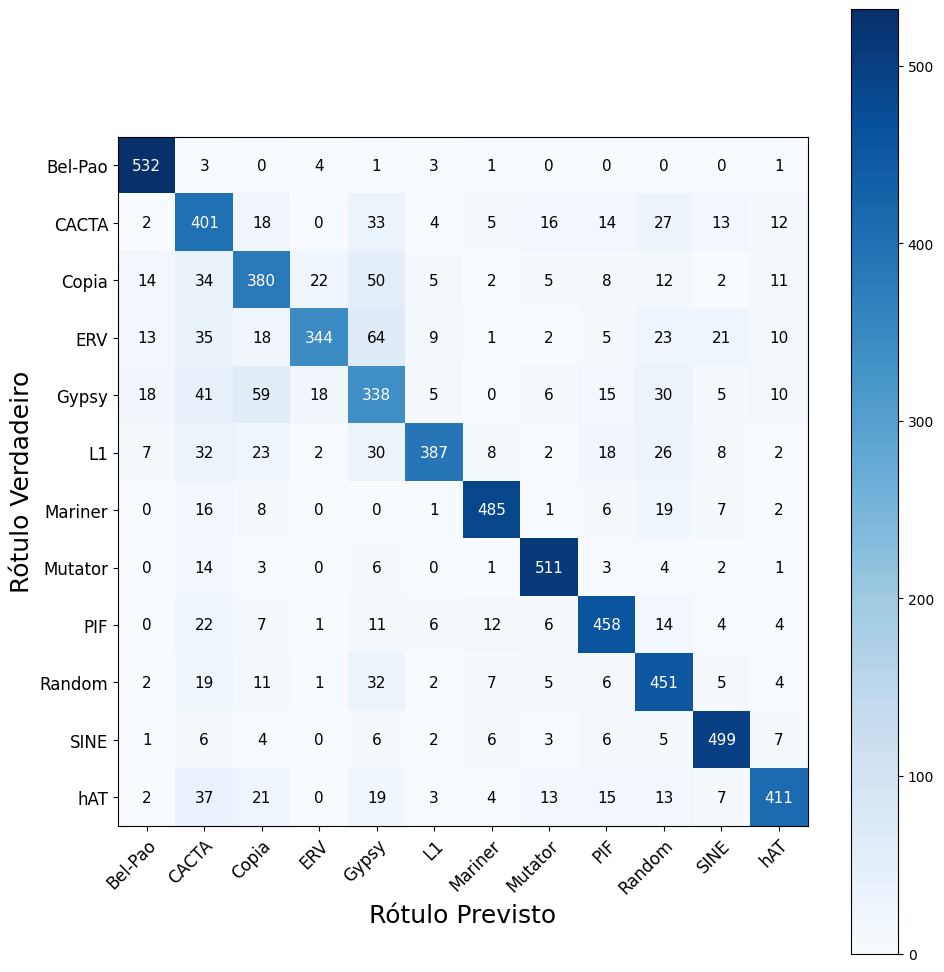

In [8]:
# ============================ TESTE (melhor checkpoint por val F1) ============================
model.load_state_dict(torch.load(CKPT_PATH, map_location=device)); model.to(device)
_, tp, tt = evaluate(test_loader, test_ds.n_sequences, with_loss=False)

print(classification_report(tt, tp, labels=list(range(NUM_CLASSES)), target_names=classes, digits=4, zero_division=0))
print(f"F1 ponderado: {f1_score(tt, tp, average='weighted', zero_division=0):.4f} | "
      f"F1 macro: {f1_score(tt, tp, average='macro', zero_division=0):.4f} | acc: {accuracy_score(tt, tp):.4f}")

cm = confusion_matrix(tt, tp, labels=list(range(NUM_CLASSES)))
fig, ax = plt.subplots(figsize=(10, 10)); im = ax.imshow(cm, cmap="Blues")
ax.set_xlabel("Rótulo Previsto", fontsize=18); ax.set_ylabel("Rótulo Verdadeiro", fontsize=18)
ax.set_xticks(range(NUM_CLASSES)); ax.set_yticks(range(NUM_CLASSES))
ax.set_xticklabels(classes, fontsize=12, rotation=45, ha="right", rotation_mode="anchor"); ax.set_yticklabels(classes, fontsize=12)
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        ax.text(j, i, int(cm[i, j]), ha="center", va="center", color="white" if i == j else "black", fontsize=11)
fig.colorbar(im, ax=ax); plt.tight_layout(); plt.show()